# Sentiment Analysis of Product Reviews
**Objective:** Build machine learning models that classify review text as positive, negative or neutral.

**Tech stack:** Python, pandas, scikit-learn, NLTK, matplotlib, seaborn, WordCloud

> **Note:** `product_reviews.csv` is a practice dataset (columns `review`, `sentiment`). For your final submission, use a real dataset from Kaggle (for example "Amazon Product Reviews", "Twitter Sentiment Analysis" or "IMDB Movie Reviews"). Change the file name and the column names in Section 1. IMDB has only positive/negative; that is fine, but then you will have 2 classes instead of 3. Large real datasets can be sampled (for example `df.sample(20000)`) to keep training fast.

In [1]:
import pandas as pd
print(pd.__version__)

3.1.1


## 0. Setup

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Load data and inspect class distribution

In [2]:
TEXT_COL = "review"
LABEL_COL = "sentiment"

df = pd.read_csv("product_reviews.csv")
df = df[[TEXT_COL, LABEL_COL]].dropna().reset_index(drop=True)
print("Shape:", df.shape)
df.sample(8, random_state=1)

Shape: (3000, 2)


,review,sentiment
1957,This headphones is defective. Do not buy it.,negative
2087,Five stars. The battery and build of the keybo...,positive
1394,Really happy with the backpack. Amazing quality!,positive
1520,"Average vacuum cleaner. Some things work, some...",neutral
1098,This coffee maker is impressive. Highly recomm...,positive
393,Got the coffee maker last week. Performance is...,neutral
28,Really happy with the water bottle. Wonderful ...,positive
99,Really happy with the phone. Superb quality!,positive


In [3]:
print(df[LABEL_COL].value_counts())
print()
print(df[LABEL_COL].value_counts(normalize=True).round(3))

sentiment
positive    1229
negative    1059
neutral      712
Name: count, dtype: int64

sentiment
positive    0.410
negative    0.353
neutral     0.237
Name: proportion, dtype: float64


## 2. Visualise the sentiment distribution
_Checklist: bar chart of sentiment distribution_

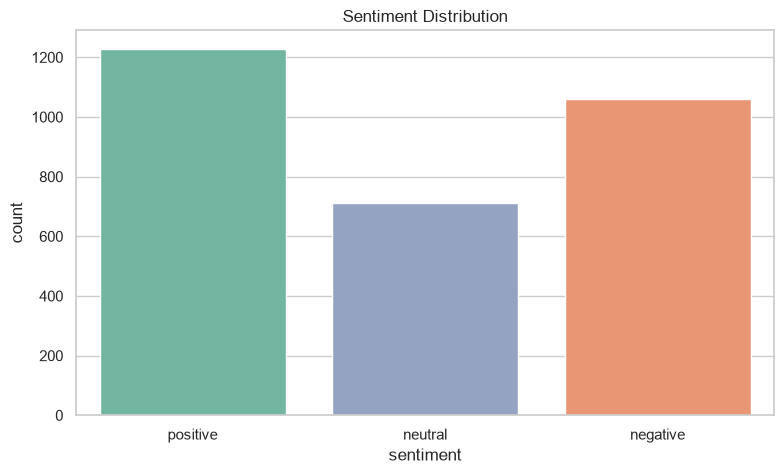

In [4]:
order = ["positive", "neutral", "negative"]
sns.countplot(data=df, x=LABEL_COL, order=order, hue=LABEL_COL, palette="Set2", legend=False)
plt.title("Sentiment Distribution")
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 3. Text preprocessing pipeline
_Checklist: lowercase, punctuation removal, stopword removal, tokenisation, lemmatization_

In [5]:
tokenizer = RegexpTokenizer(r"[a-z]+")      # keeps only letters = removes punctuation and numbers
lemmatizer = WordNetLemmatizer()

# Standard English stopwords, but KEEP negations: 'not good' must not become 'good'
negations = {"not", "no", "nor", "never", "n't", "don", "didn", "doesn", "isn", "wasn", "weren", "aren", "couldn", "wouldn", "shouldn", "won"}
stop_words = set(stopwords.words("english")) - negations

def preprocess(text):
    text = str(text).lower()
    tokens = tokenizer.tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

df["clean"] = df[TEXT_COL].apply(preprocess)
df[[TEXT_COL, "clean"]].head(8)

,review,clean
0,The headphones works fantastic and arrived early.,headphone work fantastic arrived early
1,"Flimsy coffee maker, broke within days. At lea...",flimsy coffee maker broke within day least box...
2,Five stars. The battery and build of the coffe...,five star battery build coffee maker wonderful
3,I use the blender daily. Overall adequate.,use blender daily overall adequate
4,Five stars. The battery and build of the phone...,five star battery build phone excellent
5,"The water bottle is fine, I have no strong opi...",water bottle fine no strong opinion
6,Really happy with the keyboard. Impressive qua...,really happy keyboard impressive quality canno...
7,"The water bottle is average, I have no strong ...",water bottle average no strong opinion


**Why keep the negation words?** _Standard stopword lists remove words like "not". Explain in your own words what would happen to "not good" if "not" were removed._

## 4. WordCloud for each sentiment
_Checklist: WordCloud for each sentiment class_

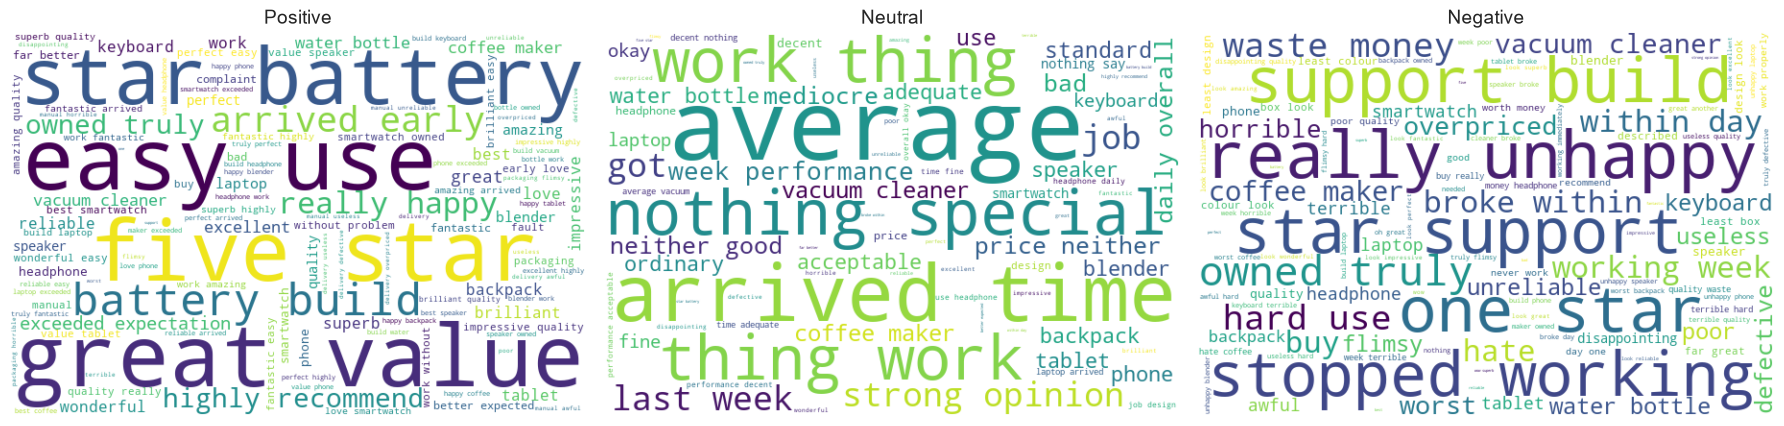

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, sent in zip(axes, order):
    text = " ".join(df.loc[df[LABEL_COL] == sent, "clean"])
    wc = WordCloud(width=600, height=400, background_color="white", colormap="viridis").generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(sent.capitalize(), fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observation:** _Which words stand out in each class? Any words that appear in all three?_

## 5. Feature extraction with TF-IDF
_Checklist: TF-IDF Vectorizer, explain its purpose_

**What is TF-IDF?** _Explain in your own words:_
- _TF (term frequency): how often a word appears in a review_
- _IDF (inverse document frequency): how rare the word is across all reviews_
- _Why multiplying them gives higher weight to words that are distinctive, and lower weight to words that appear everywhere_

In [7]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean"], df[LABEL_COL], test_size=0.2, random_state=42, stratify=df[LABEL_COL]
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)   # unigrams + bigrams
X_train = tfidf.fit_transform(X_train_text)             # fit ONLY on training text
X_test = tfidf.transform(X_test_text)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Train: (2400, 1147)  Test: (600, 1147)
Vocabulary size: 1147


**Train/test split (80/20):** _Why do we call `fit_transform` on the training text but only `transform` on the test text?_

## 6. Train the classifiers
_Checklist: Naive Bayes + Logistic Regression_

In [8]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}

preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    print(name, "trained")

Naive Bayes trained
Logistic Regression trained


## 7. Evaluate
_Checklist: accuracy, precision, recall, F1, confusion matrix for each model_

In [9]:
for name, p in preds.items():
    print("=" * 60)
    print(name, "- accuracy:", round(accuracy_score(y_test, p), 3))
    print(classification_report(y_test, p, labels=order))

Naive Bayes - accuracy: 0.978
              precision    recall  f1-score   support

    positive       0.98      0.99      0.98       246
     neutral       0.99      0.97      0.98       142
    negative       0.97      0.97      0.97       212

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.98      0.98      0.98       600

Logistic Regression - accuracy: 0.978
              precision    recall  f1-score   support

    positive       0.98      0.99      0.98       246
     neutral       0.99      0.97      0.98       142
    negative       0.97      0.97      0.97       212

    accuracy                           0.98       600
   macro avg       0.98      0.98      0.98       600
weighted avg       0.98      0.98      0.98       600



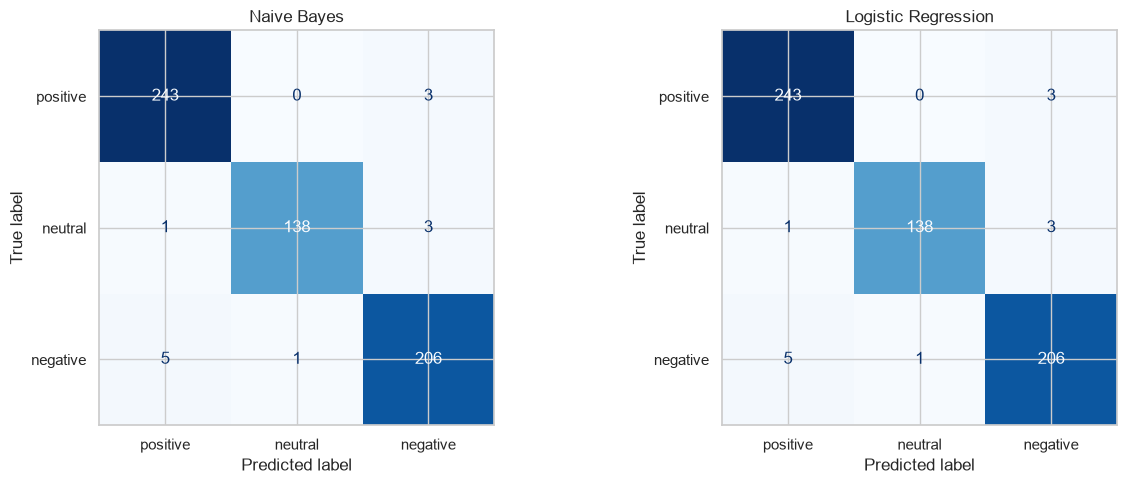

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=order)
    ConfusionMatrixDisplay(cm, display_labels=order).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Observation:** _Which model is better? Which class is hardest to predict? Check precision and recall per class._

## 8. Error analysis
_Checklist: show 5 misclassified examples and discuss why_

In [11]:
best_name = max(preds, key=lambda n: accuracy_score(y_test, preds[n]))
print("Best model:", best_name)

errors = pd.DataFrame({
    "review": df.loc[y_test.index, TEXT_COL],
    "actual": y_test,
    "predicted": preds[best_name],
})
errors = errors[errors["actual"] != errors["predicted"]]
print("Misclassified:", len(errors), "of", len(y_test))

pd.set_option("display.max_colwidth", 200)
errors.head(5)

Best model: Naive Bayes
Misclassified: 13 of 600


,review,actual,predicted
1976,Really happy with the smartwatch. Superb quality!,negative,positive
2624,"Worst water bottle I have owned, truly defective. At least the colour looks brilliant.",positive,negative
748,The vacuum cleaner stopped working after a week. Unreliable.,positive,negative
39,"Awful smartwatch, broke within days.",positive,negative
649,"Poor blender, broke within days.",neutral,negative


**Discussion:** _For each of the 5 examples, explain why the model got it wrong. Possible reasons: mixed sentiment in one review, sarcasm, neutral language that sounds positive or negative, or a wrong label in the data._

## 9. Try your own reviews

In [12]:
def predict_sentiment(text, model_name=None):
    model = models[model_name or best_name]
    return model.predict(tfidf.transform([preprocess(text)]))[0]

for sample in ["Absolutely love it, works perfectly",
               "Not good at all, broke after two days",
               "It is okay, does the job"]:
    print(f"{predict_sentiment(sample):9s} <- {sample}")

positive  <- Absolutely love it, works perfectly
negative  <- Not good at all, broke after two days
neutral   <- It is okay, does the job


## 10. Conclusion
_Which model performed best? What real-world application could this serve (for example monitoring customer feedback, prioritising support tickets or tracking brand reputation)? What would you improve (more data, a better model such as LSTM or BERT, handling sarcasm)?_